<a href="https://colab.research.google.com/github/Nihat0311/Computer-Vision/blob/main/Computer_Vision_Using_Convolutional_Neural_Network.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import numpy as np
import torch
from sklearn.datasets import load_sample_images
sample_images=np.stack(load_sample_images()['images'])
sample_images=torch.tensor(sample_images,dtype=torch.float32) /255

In [ ]:
sample_images.shape #B H W C

torch.Size([2, 427, 640, 3])

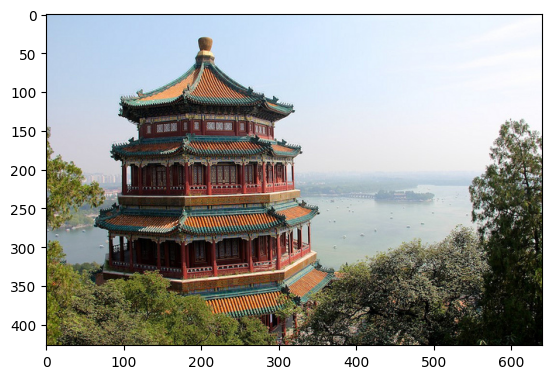

In [ ]:
import matplotlib.pyplot as plt
plt.imshow(sample_images[0])
plt.show()

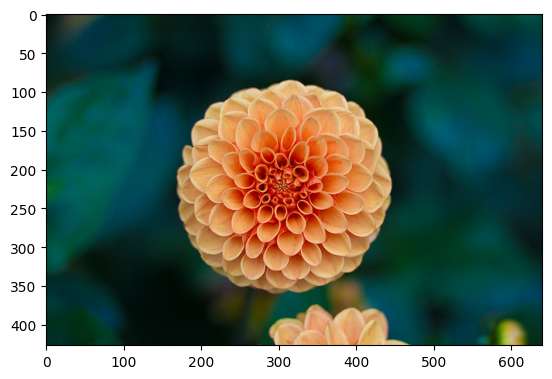

In [ ]:
plt.imshow(sample_images[1])
plt.show()

In [ ]:
#shape --> Batch(N), C,H,W

In [ ]:
#permute

In [ ]:
sample_image_permuted=sample_images.permute(0,3,1,2)
sample_image_permuted.shape

torch.Size([2, 3, 427, 640])

In [ ]:
import torchvision
import torchvision.transforms.v2 as T
cropped_images=T.CenterCrop((70,120))(sample_image_permuted)
cropped_images.shape

torch.Size([2, 3, 70, 120])

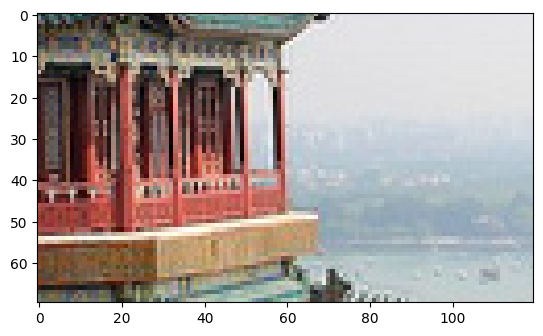

In [ ]:
plt.imshow(cropped_images[0].permute(1,2,0))
plt.show()

In [ ]:
import torch.nn as nn
torch.manual_seed(42)
conv_layer=nn.Conv2d(
    in_channels=3,   #rgb
    out_channels=32, # feature map count
    kernel_size=7,   # filter size  7x7
    stride=1,        #step
    padding='valid'  #zero padding
)

fmaps=conv_layer(cropped_images)
fmaps.shape

torch.Size([2, 32, 64, 114])

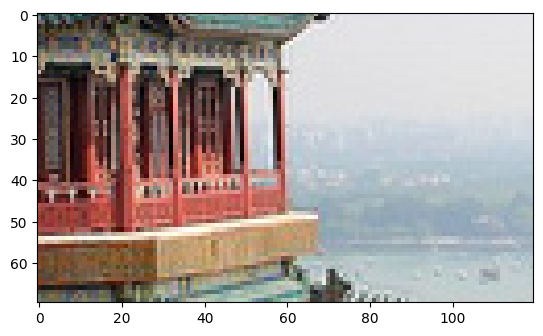

In [ ]:
plt.imshow(cropped_images[0].permute(1,2,0))
plt.show()

In [ ]:
import torch.nn as nn
torch.manual_seed(42)
conv_layer=nn.Conv2d(
    in_channels=3,   #rgb
    out_channels=32, # feature map count
    kernel_size=7,   # filter size  7x7
    stride=1,        #step
    padding='same'  #zero padding
)

fmaps=conv_layer(cropped_images)
fmaps.shape

torch.Size([2, 32, 70, 120])

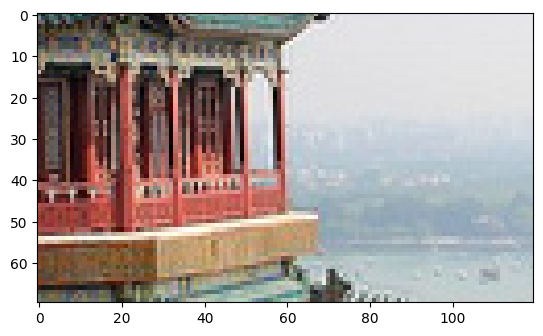

In [ ]:
plt.imshow(cropped_images[0].permute(1,2,0))
plt.show()

In [ ]:
import torch.nn as nn

In [ ]:
max_pool=nn.MaxPool2d( # H and W
    kernel_size=3
)
max_pool

MaxPool2d(kernel_size=3, stride=3, padding=0, dilation=1, ceil_mode=False)

In [ ]:
avg_pool=nn.AvgPool2d(
    kernel_size=3
)
avg_pool

AvgPool2d(kernel_size=3, stride=3, padding=0)

In [ ]:
import torch.nn.functional as F
class DeepthPool(torch.nn.Module):
  def __init__(self,kernel_size,stride=None,padding=0):
    super().__init__()
    self.kernel_size=kernel_size
    self.stride=stride if stride is not None else kernel_size
    self.padding=padding
  def forward(self,inputs):
    batch,channels,height,width=inputs.shape
    Z=inputs.view(batch,channels,height*width)
    Z=Z.permute(0,2,1)
    Z=F.max_pool1d(Z,kernel_size=self.kernel_size,stride=self.stride,padding=self.padding)
    Z=Z.permute(0,2,1)
    return Z.view(batch,-1,height,width)

In [ ]:
global_avg_pool=nn.AdaptiveAvgPool2d(
    output_size=(5,3)
)
output=global_avg_pool(cropped_images)
output.shape

torch.Size([2, 3, 5, 3])

In [ ]:
cropped_images.shape

torch.Size([2, 3, 70, 120])

In [ ]:
cropped_images.mean(dim=(2,3),keepdims=True).shape

torch.Size([2, 3, 1, 1])

In [ ]:
if torch.cuda.is_available():
  device=torch.device('cuda')
else:
  device=torch.device('cpu')

In [ ]:
from functools import partial
DefaultConv2d=partial(
    nn.Conv2d,
    kernel_size=3,
    padding='same'
    )

model=nn.Sequential(
    DefaultConv2d(in_channels=3,out_channels=64),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    DefaultConv2d(in_channels=64,out_channels=128),
    DefaultConv2d(in_channels=128,out_channels=128),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    DefaultConv2d(in_channels=128,out_channels=256),
    DefaultConv2d(in_channels=256,out_channels=256),
    nn.ReLU(),
    nn.MaxPool2d(kernel_size=2),

    nn.Flatten(),
    nn.Linear(in_features=2304,out_features=128),
    nn.ReLU(),
    nn.Dropout(0.5),

    nn.Linear(in_features=128,out_features=64),
    nn.ReLU(),

    nn.Linear(in_features=64,out_features=10)
).to(device)

In [ ]:
! curl -L -o fruits-classification.zip\
  https://www.kaggle.com/api/v1/datasets/download/utkarshsaxenadn/fruits-classification

  % Total    % Received % Xferd  Average Speed   Time    Time     Time  Current
                                 Dload  Upload   Total   Spent    Left  Speed
  0     0    0     0    0     0      0      0 --:--:-- --:--:-- --:--:--     0
100 84.8M  100 84.8M    0     0  74.9M      0  0:00:01  0:00:01 --:--:-- 74.9M


In [ ]:
!unzip /content/fruits-classification.zip

Streaming output truncated to the last 5000 lines.
  inflating: Fruits Classification/train/Grape/Grape (1950).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1952).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1953).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1955).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1956).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1957).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1958).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1959).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (196).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1960).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1961).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1962).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1963).jpeg  
  inflating: Fruits Classification/train/Grape/Grape (1964).jpeg  
  inflating:

In [ ]:
import os
import random
from pathlib import Path
from functools import partial

import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from torchvision import datasets, transforms
from tqdm.auto import tqdm
from sklearn.metrics import classification_report, confusion_matrix

In [ ]:
from pathlib import Path

DATA_ROOT=Path('/content/Fruits Classification')

train_dir=DATA_ROOT/'train'
val_dir=DATA_ROOT/'valid'
test_dir=DATA_ROOT/'test'

print(train_dir)
print(val_dir)
print(test_dir)

/content/Fruits Classification/train
/content/Fruits Classification/valid
/content/Fruits Classification/test


In [ ]:
from PIL import Image
import matplotlib.pyplot as plt

In [ ]:
classes=os.listdir('/content/Fruits Classification/train')
cls=classes[0]
cls

'Mango'

In [ ]:
classes

['Mango', 'Grape', 'Apple', 'Strawberry', 'Banana']

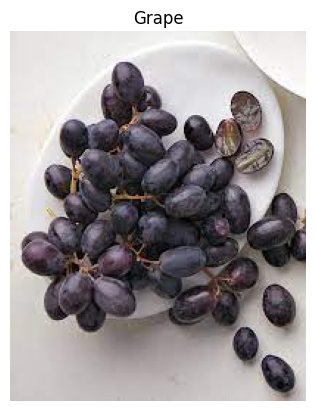

In [ ]:
img_name=os.listdir(f'/content/Fruits Classification/train/{classes[1]}')[0]
img_name

img_path=f'/content/Fruits Classification/train/{classes[1]}/{img_name}'
img=Image.open(img_path)

plt.imshow(img)
plt.title(classes[1])
plt.axis('off')
plt.show()

In [ ]:
from torchvision import transforms ,datasets

transform=transforms.Compose([
    transforms.Resize((100,100)),
    transforms.ToTensor(),
    transforms.Normalize([0.5,0.5,0.5],[0.5,0.5,0.5])
])

train_data = datasets.ImageFolder('/content/Fruits Classification/train', transform=transform)
valid_data = datasets.ImageFolder('/content/Fruits Classification/valid', transform=transform)
test_data  = datasets.ImageFolder('/content/Fruits Classification/test', transform=transform)

In [ ]:
print(len(train_data))
print(len(valid_data))
print(len(test_data))
print(train_data.classes)

9700
200
100
['Apple', 'Banana', 'Grape', 'Mango', 'Strawberry']


In [ ]:
from torch.utils.data import DataLoader
train_loader=DataLoader(train_data,batch_size=32,shuffle=True)
valid_loader=DataLoader(valid_data,batch_size=32,shuffle=False)
test_loader=DataLoader(test_data,batch_size=32,shuffle=False)

In [ ]:
DefaultConv2d=partial(
    nn.Conv2d,
    kernel_size=3,
    padding='same'
)
model=nn.Sequential(
    DefaultConv2d(3,32,kernel_size=7),
    nn.ReLU(),
    nn.MaxPool2d(2),

    DefaultConv2d(32,64),
    nn.ReLU(),
    nn.MaxPool2d(2),

    DefaultConv2d(64,128),
    nn.ReLU(),
    nn.MaxPool2d(2),

    nn.AdaptiveAvgPool2d(1),
    nn.Flatten(),
    nn.Linear(128,5)
)


In [ ]:
model=model.to(device)
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)

In [ ]:
for epoch in range(10):
  model.train()
  train_loss=0

  for x,y in train_loader:
    x=x.to(device)
    y=y.to(device)

    output=model(x)
    loss=criterion(output,y)
    loss.backward()
    optimizer.step()
    optimizer.zero_grad()

    train_loss+=loss.item()

model.eval()
val_loss=0
correct=0
total=0

with torch.no_grad():
  for x,y in valid_loader:
    x=x.to(device)
    y=y.to(device)
    output=model(x)
    loss=criterion(output,y)
    val_loss+=loss.item()

    pred=output.argmax(1)
    correct+=(pred==y).sum().item()
    total+=y.size(0)

    print(f'Epoch: {epoch+1},Train Loss: {train_loss/len(train_loader)}, Val Loss: {val_loss/len(valid_loader)}, Accuracy: {correct/total}')

Epoch: 10,Train Loss: 0.853766351350044, Val Loss: 0.8125289635998862, Accuracy: 0.69


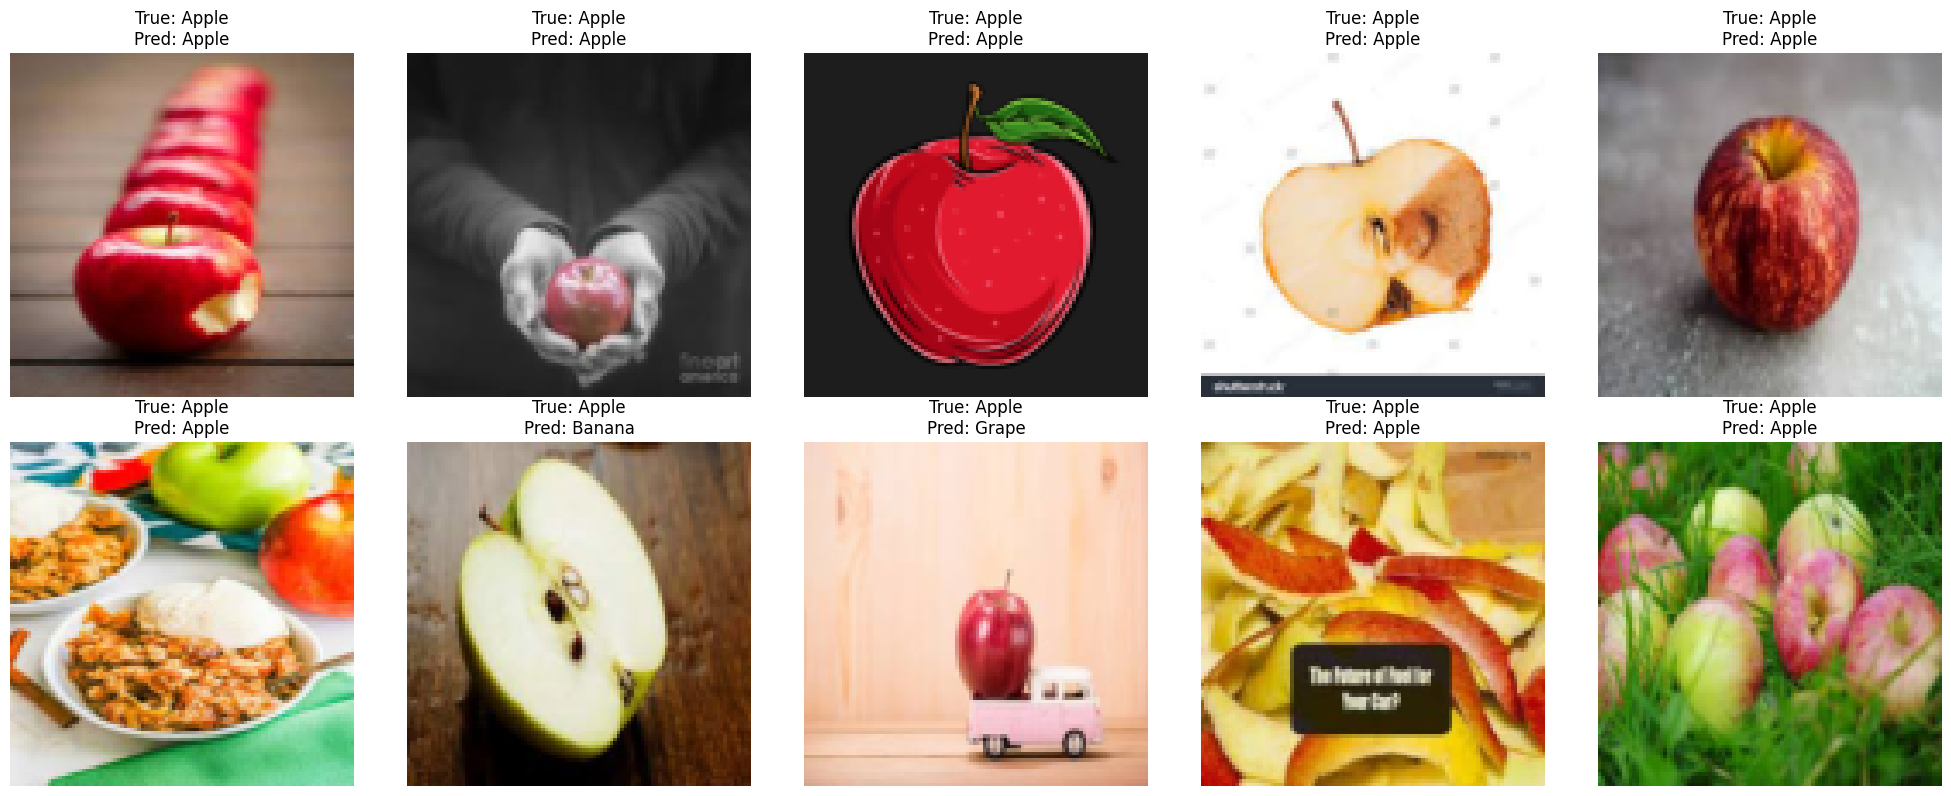

In [ ]:
import matplotlib.pyplot as plt

model.eval()

images, labels = next(iter(test_loader))
images, labels = images.to(device), labels.to(device)

with torch.no_grad():
    outputs = model(images)
    preds = outputs.argmax(1)

plt.figure(figsize=(20, 8))

for i in range(10):
    img = images[i].cpu().permute(1, 2, 0)
    img = img * 0.5 + 0.5   # normalize etmisense geri qaytarmaq ucun

    plt.subplot(2, 5, i + 1)
    plt.imshow(img)
    plt.title(f"True: {test_data.classes[labels[i]]}\nPred: {test_data.classes[preds[i]]}")
    plt.axis("off")

plt.tight_layout()
plt.show()